# Task 7 — Smart Electricity Consumption Optimizer
## One-hour-ahead power forecasting with a stacked LSTM

**Objective:** at the end of a completed 15-minute interval, use the previous
24 hours of meter readings and known calendar information to predict average
active power in the interval ending one hour later. The output is **kW**, not
kWh, a bill, or an appliance switching decision.

This notebook implements Task 7: architecture design, training, regularization,
validation-based hyperparameter selection, and evaluation. It also saves the
models and matching examples needed for Task 8's interpretation work.

**Run:** open in Google Colab, select a GPU runtime if available, and run all
cells. A CPU also works but full training can take much longer. The first run
downloads the original UCI archive (about 20 MB). It deliberately does not use
the previously interpolated or potentially truncated Task 4 CSV. Tasks 1–6
remain separate. Set `RUN_MODE = "smoke"` only to check that the pipeline runs;
smoke results are not project performance results.

No previous training results have been retained as evidence for this revision.
A full run generates its own metrics. A deeper network is not guaranteed to
outperform the basic model or persistence.

In [1]:
# Install only missing dependencies into this notebook's active environment.
import importlib.util
import subprocess
import sys

dependencies = {
    "tensorflow": "tensorflow==2.20.0",
    "numpy": "numpy>=1.26,<3",
    "pandas": "pandas>=2.2,<3",
    "sklearn": "scikit-learn>=1.5,<2",
    "matplotlib": "matplotlib>=3.8,<4",
    "joblib": "joblib>=1.4,<2",
}
missing = [spec for module, spec in dependencies.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

## 1. Configuration and reproducibility

The full run uses the entire dataset, a 70/15/15 chronological partition, two
predefined LSTM configurations, and one basic feed-forward network. All models
receive the same available information. Hyperparameters are selected using
validation RMSE only. Test results are produced after selection is frozen.
Fixed seeds improve repeatability; different TensorFlow versions and hardware
can still produce different results. Package versions are recorded per run.

In [2]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import hashlib
import json
import platform
import shutil
import time
import urllib.request
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers, regularizers

SEED = 42
RUN_MODE = "full"                         # "full" for submission; "smoke" for testing
SEQUENCE_LENGTH = 96                      # 96 completed 15-minute intervals
HORIZON = 4                               # target ends 60 minutes after forecast origin
BATCH_SIZE = 256
MAX_FORWARD_FILL = 4                      # at most one hour of missing input bins
MAX_EPOCHS = 50 if RUN_MODE == "full" else 2
TRAIN_FRACTION, VALIDATION_END_FRACTION = 0.70, 0.85
assert RUN_MODE in {"full", "smoke"}

keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    pass
# Avoid excessive CPU thread contention. A pre-initialized notebook may reject it.
try:
    tf.config.threading.set_intra_op_parallelism_threads(min(8, os.cpu_count() or 2))
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass

ROOT = Path.cwd()
DATA_DIR = ROOT / "task7_data"
DATA_DIR.mkdir(exist_ok=True)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_DIR = ROOT / "task7_outputs" / f"{RUN_MODE}_{RUN_ID}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

print("Run mode:", RUN_MODE)
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
print("Artifacts:", OUTPUT_DIR)
if RUN_MODE == "smoke":
    print("SMOKE TEST ONLY: fewer examples and epochs; do not report these as final results.")

Run mode: full
TensorFlow: 2.20.0 | GPUs: []
Artifacts: C:\Users\Gaurav Choithramani\Desktop\cil\task7_outputs\full_20261004T220408_123740Z


## 2. Load and audit the complete original dataset

Source: [UCI Individual Household Electric Power Consumption](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption),
Hebrail and Berard, DOI [10.24432/C58K54](https://doi.org/10.24432/C58K54),
licensed CC BY 4.0. It contains 2,075,259 minute-level records from one household
in France, December 2006–November 2010. It does not measure this project's
example Mumbai household. This limits generalization and local cost claims.

The row-count check catches partial downloads or accidental subset inputs.
The original archive is retained with its SHA-256 for reproducibility. Only
timestamps and active power are read; no invented occupancy or weather is used.

In [3]:
SOURCE_URL = (
    "https://archive.ics.uci.edu/static/public/235/"
    "individual%2Bhousehold%2Belectric%2Bpower%2Bconsumption.zip"
)
ARCHIVE = DATA_DIR / "household_power_consumption.zip"
EXPECTED_RAW_ROWS = 2_075_259
if not ARCHIVE.exists():
    temporary_archive = ARCHIVE.with_suffix(".download")
    request = urllib.request.Request(SOURCE_URL, headers={"User-Agent": "Task7-Electricity-Project/1.0"})
    with urllib.request.urlopen(request, timeout=180) as response, temporary_archive.open("wb") as dest:
        shutil.copyfileobj(response, dest)
    if not zipfile.is_zipfile(temporary_archive):
        raise ValueError("Download was not a valid ZIP archive; check the UCI source URL.")
    temporary_archive.replace(ARCHIVE)

with zipfile.ZipFile(ARCHIVE) as archive:
    with archive.open("household_power_consumption.txt") as member:
        raw = pd.read_csv(member, sep=";", usecols=["Date", "Time", "Global_active_power"],
                          na_values=["?"], low_memory=False)
assert len(raw) == EXPECTED_RAW_ROWS, (
    f"Expected the full UCI data ({EXPECTED_RAW_ROWS:,} rows), got {len(raw):,}. "
    "Verify the cached raw archive before proceeding."
)

raw["Datetime"] = pd.to_datetime(raw["Date"] + " " + raw["Time"],
                                format="%d/%m/%Y %H:%M:%S", errors="coerce")
raw["Global_active_power"] = pd.to_numeric(raw["Global_active_power"], errors="coerce")
invalid_times = int(raw["Datetime"].isna().sum())
duplicate_times = int(raw["Datetime"].duplicated().sum())
assert invalid_times == 0 and duplicate_times == 0, "Resolve timestamp errors before modeling."
raw = raw.sort_values("Datetime").set_index("Datetime")
invalid_power = (~np.isfinite(raw["Global_active_power"])) | (raw["Global_active_power"] < 0)
raw.loc[invalid_power, "Global_active_power"] = np.nan

data_audit = {
    "source_url": SOURCE_URL,
    "archive_sha256": hashlib.sha256(ARCHIVE.read_bytes()).hexdigest(),
    "raw_rows": int(len(raw)),
    "raw_start": str(raw.index.min()), "raw_end": str(raw.index.max()),
    "missing_or_invalid_power_rows": int(invalid_power.sum()),
    "invalid_timestamps": invalid_times, "duplicate_timestamps": duplicate_times,
}
display(pd.Series(data_audit, name="Data audit"))

source_url                       https://archive.ics.uci.edu/static/public/235/...
archive_sha256                   9f84b46ade8a2d8e1286ec4b2b6c2987a45a755c59f263...
raw_rows                                                                   2075259
raw_start                                                      2006-12-16 17:24:00
raw_end                                                        2010-11-26 21:02:00
missing_or_invalid_power_rows                                                25979
invalid_timestamps                                                               0
duplicate_timestamps                                                             0
Name: Data audit, dtype: object

source_url                       https://archive.ics.uci.edu/static/public/235/...
archive_sha256                   9f84b46ade8a2d8e1286ec4b2b6c2987a45a755c59f263...
raw_rows                                                                   2075259
raw_start                                                      2006-12-16 17:24:00
raw_end                                                        2010-11-26 21:02:00
missing_or_invalid_power_rows                                                25979
invalid_timestamps                                                               0
duplicate_timestamps                                                             0
Name: Data audit, dtype: object


## 3. Causal preprocessing and interval timestamps

Each value is the mean of a **completed** interval. The bin [10:00, 10:15) is
labeled 10:15, when all of its readings are available. At 10:15, the target is
the mean for [11:00, 11:15), labeled 11:15. This is an interval-power forecast,
not an instantaneous reading or total energy over the next hour.

A bin is observed only when it has all 15 valid minute readings. Incomplete
bins can be forward-filled for at most four intervals, using past values only.
Longer gaps stay missing and affected input windows are excluded. The model
receives an observed/missing flag. **Targets are never imputed:** only fully
observed target bins are scored. No interpolation, backward filling, or clipping
of genuine high-usage observations is performed.

interval_rows                     138352
fully_observed_intervals          136551
forward_filled_input_intervals       113
unfilled_input_intervals            1688
dtype: object

interval_rows                     138352
fully_observed_intervals          136551
forward_filled_input_intervals       113
unfilled_input_intervals            1688
dtype: object


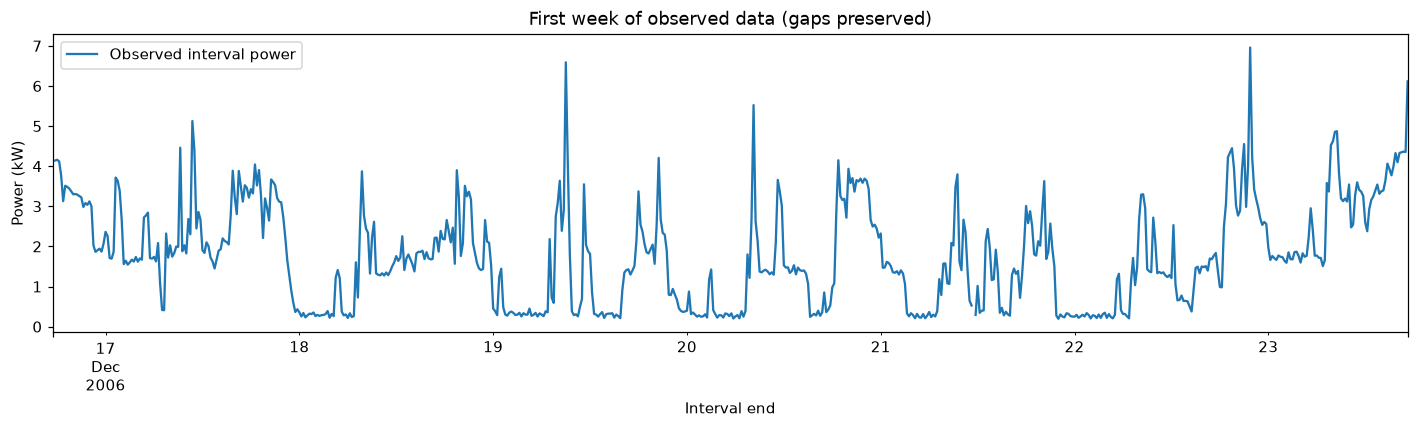

In [4]:
def prepare_power(minute_series, max_forward_fill=4):
    if not minute_series.index.is_unique or not minute_series.index.is_monotonic_increasing:
        raise ValueError("Minute readings must have unique, sorted timestamps.")
    minute_series = minute_series.where(np.isfinite(minute_series) & (minute_series >= 0))
    bins = minute_series.resample("15min", closed="left", label="right")
    stats = bins.agg(["mean", "count"])
    stats["observed"] = stats["count"].eq(15)
    stats["actual_kw"] = stats["mean"].where(stats["observed"])
    stats["input_kw"] = stats["actual_kw"].ffill(limit=max_forward_fill)
    return stats

power = prepare_power(raw["Global_active_power"], MAX_FORWARD_FILL)
data_audit.update({
    "interval_rows": int(len(power)),
    "fully_observed_intervals": int(power["observed"].sum()),
    "forward_filled_input_intervals": int((power["actual_kw"].isna() & power["input_kw"].notna()).sum()),
    "unfilled_input_intervals": int(power["input_kw"].isna().sum()),
})
display(pd.Series(data_audit).tail(4))
fig, ax = plt.subplots(figsize=(13, 4))
power["actual_kw"].iloc[:7 * 96].plot(ax=ax, label="Observed interval power")
ax.set(title="First week of observed data (gaps preserved)", xlabel="Interval end", ylabel="Power (kW)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "data_first_week.png", dpi=150)
plt.show()

## 4. Inputs and chronological partitions

The LSTM receives 96 past intervals containing power, an observation flag, and
cyclical hour/day-of-week features. A second input supplies recent averages,
variation, daily/weekly lags, and the target interval's known calendar features.
Calendar values for a future time are known at forecast issuance; future meter
readings are not. Daily/weekly seasonal features refer to the target clock slot
on a previous day/week, both earlier than the forecast origin.

Partitions use target times. Four target intervals are excluded at the start of
validation and test, so the first forecast origin is after the preceding
partition's labels. Historical windows can cross a partition boundary because
those readings are already available. Evaluation is **rolling-origin**: later
test forecasts can use earlier observed test readings, with model weights fixed.
It is not a forecast of the entire test period made on its first day.

In [5]:
def calendar_features(index):
    hour = index.hour + index.minute / 60.0
    return pd.DataFrame({
        "hour_sin": np.sin(2 * np.pi * hour / 24),
        "hour_cos": np.cos(2 * np.pi * hour / 24),
        "dow_sin": np.sin(2 * np.pi * index.dayofweek / 7),
        "dow_cos": np.cos(2 * np.pi * index.dayofweek / 7),
        "month_sin": np.sin(2 * np.pi * (index.month - 1) / 12),
        "month_cos": np.cos(2 * np.pi * (index.month - 1) / 12),
        "weekend": (index.dayofweek >= 5).astype(float),
    }, index=index)

def build_context(power_frame, horizon=4):
    p = power_frame["input_kw"]
    # Rows are indexed by TARGET time; every meter-derived feature precedes origin.
    frame = pd.DataFrame({
        "latest_kw": p.shift(horizon),
        "one_hour_before_origin_kw": p.shift(horizon + 4),
        "two_hours_before_origin_kw": p.shift(horizon + 8),
        "target_slot_previous_day_kw": p.shift(96),
        "target_slot_previous_week_kw": p.shift(672),
        "mean_previous_hour_kw": p.rolling(4).mean().shift(horizon),
        "mean_previous_4hours_kw": p.rolling(16).mean().shift(horizon),
        "mean_previous_day_kw": p.rolling(96).mean().shift(horizon),
        "std_previous_day_kw": p.rolling(96).std(ddof=0).shift(horizon),
        "observed_fraction_previous_day": power_frame["observed"].rolling(96).mean().shift(horizon),
    }, index=power_frame.index)
    return frame.join(calendar_features(frame.index).add_prefix("target_"))

context = build_context(power, HORIZON)
CONTEXT_FEATURES = context.columns.tolist()
n = len(power)
train_end = int(n * TRAIN_FRACTION)
val_end = int(n * VALIDATION_END_FRACTION)

def valid_target_indices(power_frame, context_frame, sequence_length=96, horizon=4):
    targets = np.arange(len(power_frame), dtype=np.int64)
    ends = targets - horizon + 1             # exclusive end of historical window
    starts = ends - sequence_length
    missing = power_frame["input_kw"].isna().to_numpy().astype(np.int64)
    cumulative = np.r_[0, np.cumsum(missing)]
    bounds_ok = starts >= 0
    safe_start = np.maximum(starts, 0)
    safe_end = np.maximum(ends, 0)
    window_ok = (cumulative[safe_end] - cumulative[safe_start]) == 0
    context_ok = np.isfinite(context_frame.to_numpy()).all(axis=1)
    eligible = bounds_ok & window_ok & context_ok & power_frame["observed"].to_numpy()
    return targets[eligible]

all_indices = valid_target_indices(power, context, SEQUENCE_LENGTH, HORIZON)
split_indices = {
    "train": all_indices[all_indices < train_end],
    "validation": all_indices[(all_indices >= train_end + HORIZON) & (all_indices < val_end)],
    "test": all_indices[all_indices >= val_end + HORIZON],
}
full_split_counts = {name: int(len(ids)) for name, ids in split_indices.items()}
if RUN_MODE == "smoke":
    # Evenly spaced eligible examples from each original partition; never random splitting.
    for name, cap in [("train", 2048), ("validation", 512), ("test", 512)]:
        ids = split_indices[name]
        split_indices[name] = ids[np.linspace(0, len(ids)-1, min(cap, len(ids)), dtype=int)]

train_indices, val_indices, test_indices = (split_indices[k] for k in ("train", "validation", "test"))
assert all(len(ids) > 0 for ids in split_indices.values())
assert train_indices[-1] < val_indices[0] - HORIZON
assert val_indices[-1] < test_indices[0] - HORIZON
split_table = pd.DataFrame([
    {"Split": name, "Eligible_samples_full": full_split_counts[name], "Used_samples": len(ids),
     "First_target": power.index[ids[0]], "Last_target": power.index[ids[-1]],
     "First_forecast_origin": power.index[ids[0] - HORIZON]}
    for name, ids in split_indices.items()
])
display(split_table)
split_table.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)

,Split,Eligible_samples_full,Used_samples,First_target,Last_target,First_forecast_origin
0,train,94551,94551,2006-12-23 17:45:00,2009-09-20 12:45:00,2006-12-23 16:45:00
1,validation,19858,19858,2009-09-20 14:00:00,2010-04-24 17:00:00,2009-09-20 13:00:00
2,test,18889,18889,2010-04-24 18:15:00,2010-11-26 21:00:00,2010-04-24 17:15:00


        Split  Eligible_samples_full  ...         Last_target First_forecast_origin
0       train                  94551  ... 2009-09-20 12:45:00   2006-12-23 16:45:00
1  validation                  19858  ... 2010-04-24 17:00:00   2009-09-20 13:00:00
2        test                  18889  ... 2010-11-26 21:00:00   2010-04-24 17:15:00

[3 rows x 6 columns]


## 5. Scale using training data and create batches

A power scaler is fitted to observed readings in the training period only.
Context scaling is fitted to training examples only. Cyclical values and flags
remain in their natural ranges. Windows are gathered one batch at a time,
avoiding a large duplicated array of every overlapping sequence.

Training batches are shuffled with a fixed seed. This is safe for a stateless
LSTM: order **inside each sequence** is preserved, and no rows move between
training, validation, and test. Validation and test stay in chronological order.

In [6]:
power_scaler = StandardScaler()
power_scaler.fit(power["actual_kw"].iloc[:train_end].dropna().to_numpy().reshape(-1, 1))
context_scaler = StandardScaler().fit(context.iloc[train_indices])

calendar = calendar_features(power.index)
HISTORY_FEATURES = ["power_scaled", "observed", "hour_sin", "hour_cos", "dow_sin", "dow_cos"]
history_values = np.column_stack([
    power_scaler.transform(power[["input_kw"]].to_numpy()).ravel(),
    power["observed"].to_numpy(dtype=float),
    calendar[["hour_sin", "hour_cos", "dow_sin", "dow_cos"]].to_numpy(),
]).astype(np.float32)
context_values = context_scaler.transform(context).astype(np.float32)
target_scaled = power_scaler.transform(power[["actual_kw"]].to_numpy()).astype(np.float32)

# Invalid rows remain NaN in the saved series; eligible batches never contain them.
history_tensor = tf.constant(history_values)
context_tensor = tf.constant(context_values)
target_tensor = tf.constant(target_scaled)
window_offsets = tf.range(SEQUENCE_LENGTH, dtype=tf.int64)

def inputs_for_indices(ids):
    ids = np.asarray(ids, dtype=np.int64)
    window_ids = ids[:, None] - HORIZON - SEQUENCE_LENGTH + 1 + np.arange(SEQUENCE_LENGTH)
    return {"history": history_values[window_ids], "context": context_values[ids]}

def make_dataset(ids, training=False, include_targets=True):
    dataset = tf.data.Dataset.from_tensor_slices(np.asarray(ids, dtype=np.int64))
    if training:
        dataset = dataset.shuffle(min(len(ids), 8192), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    def gather_batch(batch_ids):
        positions = batch_ids[:, None] - HORIZON - SEQUENCE_LENGTH + 1 + window_offsets[None, :]
        features = {"history": tf.gather(history_tensor, positions),
                    "context": tf.gather(context_tensor, batch_ids)}
        return (features, tf.gather(target_tensor, batch_ids)) if include_targets else features
    dataset = dataset.map(gather_batch, num_parallel_calls=2, deterministic=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return dataset.with_options(options).prefetch(1)

train_ds = make_dataset(train_indices, training=True)
val_ds = make_dataset(val_indices)
for features, targets in train_ds.take(1):
    assert tuple(features["history"].shape[1:]) == (96, len(HISTORY_FEATURES))
    assert np.isfinite(features["history"].numpy()).all()
    assert np.isfinite(features["context"].numpy()).all()
    assert np.isfinite(targets.numpy()).all()
    print("History batch:", features["history"].shape, "| Context batch:", features["context"].shape)

Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: closure mismatch, requested ('include_targets',), but source function had ()
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: closure mismatch, requested ('include_targets',), but source function had ()
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


History batch: (256, 96, 6) | Context batch: (256, 17)


## 6. Architecture and bounded hyperparameter search

**Advanced model:** history → LSTM → dropout → LSTM → dropout; this learned
representation is concatenated with the context input, followed by a dense
layer and a single linear output. Named layers allow Task 8 to inspect LSTM
activations. Dropout and L2 penalization reduce overfitting; gradient clipping
stabilizes training. The linear output is in standardized power units.

**Basic model:** flatten the same historical inputs, concatenate the same
context, then use two dense layers. Giving both networks identical inputs,
targets, and partitions isolates the difference in architecture more fairly.

Two LSTM configurations are compared; this is a bounded validation experiment,
not an exhaustive search or a guarantee of the best possible architecture.
Early stopping and learning-rate reduction monitor validation MSE, excluding
the L2 term. Best weights are restored. The test set is not used here.

In [ ]:
LSTM_CONFIGS = [
    {"name": "lstm_compact", "units": [32, 16], "dropout": 0.15, "l2": 1e-5, "lr": 1e-3},
    {"name": "lstm_stacked", "units": [64, 32], "dropout": 0.20, "l2": 1e-4, "lr": 5e-4},
]

def build_model(kind, config):
    history_input = keras.Input((SEQUENCE_LENGTH, len(HISTORY_FEATURES)), name="history")
    context_input = keras.Input((len(CONTEXT_FEATURES),), name="context")
    penalty = regularizers.l2(config["l2"])
    if kind == "lstm":
        h = layers.LSTM(config["units"][0], return_sequences=True,
                        kernel_regularizer=penalty, name="lstm_temporal_features")(history_input)
        h = layers.Dropout(config["dropout"], name="sequence_dropout")(h)
        h = layers.LSTM(config["units"][1], kernel_regularizer=penalty,
                        name="lstm_summary")(h)
        h = layers.Dropout(config["dropout"], name="summary_dropout")(h)
        h = layers.Concatenate(name="history_and_context")([h, context_input])
        h = layers.Dense(32, activation="relu", kernel_regularizer=penalty, name="dense_features")(h)
    else:
        h = layers.Flatten(name="flatten_history")(history_input)
        h = layers.Concatenate(name="history_and_context")([h, context_input])
        h = layers.Dense(64, activation="relu", kernel_regularizer=penalty, name="dense_features")(h)
        h = layers.Dropout(config["dropout"])(h)
        h = layers.Dense(32, activation="relu", kernel_regularizer=penalty)(h)
    output = layers.Dense(1, name="forecast_scaled")(h)
    network = keras.Model(inputs={"history": history_input, "context": context_input}, outputs=output,
                          name=config["name"])
    network.compile(optimizer=keras.optimizers.Adam(learning_rate=config["lr"], clipnorm=1.0),
                    loss="mse", metrics=[keras.metrics.MeanSquaredError(name="mse"),
                                         keras.metrics.MeanAbsoluteError(name="mae")])
    return network

def regression_metrics(actual, prediction):
    actual, prediction = np.asarray(actual).ravel(), np.asarray(prediction).ravel()
    assert len(actual) == len(prediction) and np.isfinite(actual).all() and np.isfinite(prediction).all()
    return {"MAE_kW": float(mean_absolute_error(actual, prediction)),
            "MSE_kW2": float(mean_squared_error(actual, prediction)),
            "RMSE_kW": float(np.sqrt(mean_squared_error(actual, prediction))),
            "R2": float(r2_score(actual, prediction))}

def predict_kw(network, ids):
    scaled = network.predict(make_dataset(ids, include_targets=False), verbose=0)
    raw_prediction = power_scaler.inverse_transform(scaled).ravel()
    # Physical non-negativity is specified before validation/test, not tuned afterward.
    return np.maximum(raw_prediction, 0.0), float(np.mean(raw_prediction < 0))

histories, fit_records, trained_paths = {}, [], {}
validation_predictions = {}
actual_val = power["actual_kw"].iloc[val_indices].to_numpy()
basic_config = {"name": "basic_mlp", "dropout": 0.20, "l2": 1e-4, "lr": 1e-3}
for kind, config in [("mlp", basic_config)] + [("lstm", c) for c in LSTM_CONFIGS]:
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    network = build_model(kind, config)
    network.summary()
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_mse", patience=7, min_delta=1e-5,
                                      restore_best_weights=True, mode="min", verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_mse", factor=0.5, patience=3,
                                          min_lr=1e-5, mode="min", verbose=1),
        keras.callbacks.TerminateOnNaN(),
    ]
    started = time.perf_counter()
    fitted = network.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
                         callbacks=callbacks, verbose=2)
    elapsed = time.perf_counter() - started
    if not all(np.isfinite(fitted.history["val_mse"])):
        raise RuntimeError("Non-finite training/validation metrics: investigate before evaluating test data.")
    history_frame = pd.DataFrame(fitted.history)
    history_frame.index = np.arange(1, len(history_frame) + 1)
    history_frame.index.name = "Epoch"
    history_frame.to_csv(OUTPUT_DIR / f"{config['name']}_history.csv")
    histories[config["name"]] = history_frame
    path = OUTPUT_DIR / f"{config['name']}.keras"
    network.save(path)
    trained_paths[config["name"]] = path
    val_prediction, clipped_fraction = predict_kw(network, val_indices)
    validation_predictions[config["name"]] = val_prediction
    fit_records.append({"Model": config["name"], "Kind": kind,
                        **regression_metrics(actual_val, val_prediction),
                        "Epochs": len(history_frame),
                        "Best_epoch": int(np.argmin(fitted.history["val_mse"]) + 1),
                        "Parameters": int(network.count_params()), "Training_seconds": elapsed,
                        "Clipped_fraction": clipped_fraction})
    del network

validation_results = pd.DataFrame(fit_records).sort_values("RMSE_kW")
selected_lstm_name = validation_results.loc[validation_results["Kind"].eq("lstm")].iloc[0]["Model"]
validation_results.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)
display(validation_results)
print("LSTM selected using validation RMSE:", selected_lstm_name)

## 7. Freeze selection and evaluate the untouched test period

Persistence uses the last observed-at-origin input value. Daily and weekly
seasonal baselines use the same target clock slot one day/week earlier. All
models are scored on exactly the same eligible targets. Baselines can win;
the notebook reports that honestly. Their historical values may use the same
bounded forward fill as the neural inputs.

Model selection is recorded before computing test predictions. The selected
LSTM remains the Task 7 model even if a baseline performs better. Do not tune
repeatedly after inspecting test scores; that would turn test into validation.

In [ ]:
BASELINE_COLUMNS = {
    "Persistence": "latest_kw",
    "Daily seasonal": "target_slot_previous_day_kw",
    "Weekly seasonal": "target_slot_previous_week_kw",
}
for name, column in BASELINE_COLUMNS.items():
    validation_predictions[name] = context[column].iloc[val_indices].to_numpy()

selection_candidates = ["basic_mlp", selected_lstm_name, *BASELINE_COLUMNS]
selected_overall_name = min(selection_candidates, key=lambda name:
                            regression_metrics(actual_val, validation_predictions[name])["RMSE_kW"])
selection_record = {"selected_lstm": selected_lstm_name,
                    "selected_overall_on_validation": selected_overall_name,
                    "selection_metric": "validation RMSE in kW after fixed non-negative clipping",
                    "run_mode": RUN_MODE}
(OUTPUT_DIR / "selection.json").write_text(json.dumps(selection_record, indent=2), encoding="utf-8")

model = keras.models.load_model(trained_paths[selected_lstm_name])
basic_model = keras.models.load_model(trained_paths["basic_mlp"])
actual_test = power["actual_kw"].iloc[test_indices].to_numpy()
test_predictions = {}
test_clipped = {}
for name, network in [(selected_lstm_name, model), ("basic_mlp", basic_model)]:
    test_predictions[name], test_clipped[name] = predict_kw(network, test_indices)
for name, column in BASELINE_COLUMNS.items():
    test_predictions[name] = context[column].iloc[test_indices].to_numpy()
    test_clipped[name] = 0.0

test_results = pd.DataFrame([
    {"Model": name, **regression_metrics(actual_test, prediction),
     "Clipped_fraction": test_clipped[name]} for name, prediction in test_predictions.items()
])
persistence_rmse = float(test_results.set_index("Model").loc["Persistence", "RMSE_kW"])
test_results["RMSE_improvement_vs_persistence_pct"] = (
    100 * (1 - test_results["RMSE_kW"] / persistence_rmse) if persistence_rmse > 0 else np.nan
)
test_results["Selected_on_validation"] = test_results["Model"].eq(selected_overall_name)
test_results.to_csv(OUTPUT_DIR / "test_model_comparison.csv", index=False)
display(test_results.round(4))
print("Overall model selected BEFORE test:", selected_overall_name)
if RUN_MODE == "smoke":
    print("These are pipeline smoke-test metrics, not final project results.")

## 8. Training curves and error analysis

Training/validation MSE is in standardized units; final forecast errors are in
kW. A lower validation loss can reflect different seasons and dropout being
disabled at inference, so it does not by itself prove absence of overfitting.
Plot labels refer to target interval ends. Positive residuals mean underprediction.
High-demand thresholds are derived from observed **training** readings only.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name in zip(axes, [selected_lstm_name, "basic_mlp"]):
    histories[name][["mse", "val_mse"]].plot(ax=ax)
    ax.set(title=name, xlabel="Epoch", ylabel="MSE (standardized power)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "learning_curves.png", dpi=150)
plt.show()

prediction_frame = pd.DataFrame({
    "Forecast_origin": power.index[test_indices - HORIZON],
    "Target_interval_end": power.index[test_indices],
    "Actual_kW": actual_test,
    **{f"{name}_kW": values for name, values in test_predictions.items()},
})
prediction_frame["LSTM_residual_kW"] = actual_test - test_predictions[selected_lstm_name]
prediction_frame.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
# Reindex before plotting so missing intervals appear as gaps rather than joined lines.
plotted = prediction_frame.set_index("Target_interval_end")
first_time = plotted.index[0]
view = plotted.loc[:first_time + pd.Timedelta(days=7)].reindex(
    pd.date_range(first_time, first_time + pd.Timedelta(days=7), freq="15min"))
view[["Actual_kW", f"{selected_lstm_name}_kW", "Persistence_kW"]].plot(ax=axes[0])
axes[0].set(title="First test week: observed and predicted power", ylabel="Power (kW)", xlabel="Target interval end")
axes[1].hist(prediction_frame["LSTM_residual_kW"], bins=60, edgecolor="white")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set(title="LSTM error distribution", xlabel="Actual minus predicted (kW)", ylabel="Count")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "forecast_and_residuals.png", dpi=150)
plt.show()

peak_threshold = float(power["actual_kw"].iloc[:train_end].quantile(0.90))
error_records = []
for segment, mask in {
    "All test targets": np.ones(len(actual_test), dtype=bool),
    "High demand (above training 90th percentile)": actual_test >= peak_threshold,
    "Other demand": actual_test < peak_threshold,
}.items():
    if int(mask.sum()) >= 2:
        for name, prediction in test_predictions.items():
            error_records.append({"Segment": segment, "Model": name, "Samples": int(mask.sum()),
                                  **regression_metrics(actual_test[mask], prediction[mask])})
error_by_segment = pd.DataFrame(error_records)
error_by_segment.to_csv(OUTPUT_DIR / "error_by_demand_segment.csv", index=False)
display(error_by_segment.round(4))
print("High-demand threshold from training:", round(peak_threshold, 3), "kW")

## 9. Save a reproducible handoff for Task 8

The output folder includes the selected LSTM, basic network, preprocessing
scalers, feature names, split indices, prepared time series, predictions,
training histories, data audit, and configuration. It also includes up to 128
training background examples and 256 evenly spaced test examples for later
interpretation. They are deterministic samples, not hand-picked successes.
`lstm_temporal_features` and `lstm_summary` expose useful activation outputs.

Interpretation itself belongs to Task 8. An activation or attribution shows
model behavior; it does not prove that a feature causes household consumption.

In [ ]:
model.save(OUTPUT_DIR / "task7_lstm.keras")
basic_model.save(OUTPUT_DIR / "task7_basic_mlp.keras")
joblib.dump(power_scaler, OUTPUT_DIR / "power_scaler.joblib")
joblib.dump(context_scaler, OUTPUT_DIR / "context_scaler.joblib")
power.to_csv(OUTPUT_DIR / "power_15min.csv", index_label="Interval_end")
np.savez_compressed(OUTPUT_DIR / "prepared_arrays.npz",
                    history_values=history_values, context_values=context_values,
                    target_scaled=target_scaled,
                    timestamps_ns=power.index.asi8,
                    train_indices=train_indices, validation_indices=val_indices, test_indices=test_indices)

def evenly_spaced(ids, cap):
    return ids[np.linspace(0, len(ids)-1, min(cap, len(ids)), dtype=int)]

background_indices = evenly_spaced(train_indices, 128)
explain_indices = evenly_spaced(test_indices, 256)
background = inputs_for_indices(background_indices)
explain = inputs_for_indices(explain_indices)
np.savez_compressed(OUTPUT_DIR / "task8_examples.npz",
                    background_history=background["history"], background_context=background["context"],
                    background_indices=background_indices,
                    explain_history=explain["history"], explain_context=explain["context"],
                    explain_indices=explain_indices,
                    explain_actual_kw=power["actual_kw"].iloc[explain_indices].to_numpy(),
                    explain_target_timestamps_ns=power.index[explain_indices].asi8)

run_manifest = {
    "run_id": RUN_ID, "run_mode": RUN_MODE, "seed": SEED,
    "data_audit": data_audit, "sequence_length": SEQUENCE_LENGTH, "horizon_steps": HORIZON,
    "interval_minutes": 15, "target": "mean active power in interval ending 1 hour after origin",
    "units": "kW", "timestamp_semantics": "right-labeled, left-closed completed intervals",
    "target_imputation": "none; require 15 observed minute readings",
    "input_imputation": f"past-only forward fill limited to {MAX_FORWARD_FILL} bins",
    "split_fractions": [TRAIN_FRACTION, VALIDATION_END_FRACTION - TRAIN_FRACTION,
                         1 - VALIDATION_END_FRACTION],
    "train_end_position_exclusive": train_end, "validation_end_position_exclusive": val_end,
    "boundary_gap_target_steps": HORIZON, "full_eligible_split_counts": full_split_counts,
    "used_split_counts": {name: len(ids) for name, ids in split_indices.items()},
    "history_features": HISTORY_FEATURES, "context_features": CONTEXT_FEATURES,
    "lstm_candidates": LSTM_CONFIGS, "basic_config": basic_config,
    "max_epochs": MAX_EPOCHS, "batch_size": BATCH_SIZE,
    "selection": selection_record, "prediction_postprocessing": "inverse scale then clip at zero",
    "peak_threshold_kw": peak_threshold,
    "versions": {"python": platform.python_version(), "tensorflow": tf.__version__,
                 "keras": keras.__version__, "numpy": np.__version__, "pandas": pd.__version__,
                 "scikit_learn": sklearn.__version__},
}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(run_manifest, indent=2), encoding="utf-8")
(OUTPUT_DIR / "data_audit.json").write_text(json.dumps(data_audit, indent=2), encoding="utf-8")
validation_prediction_frame = pd.DataFrame({
    "Forecast_origin": power.index[val_indices-HORIZON],
    "Target_interval_end": power.index[val_indices], "Actual_kW": actual_val,
    **{f"{name}_kW": pred for name, pred in validation_predictions.items()},
})
validation_prediction_frame.to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)

# Verify that a fresh load reproduces predictions and exposes Task 8 activations.
reloaded = keras.models.load_model(OUTPUT_DIR / "task7_lstm.keras")
probe_inputs = inputs_for_indices(test_indices[:8])
np.testing.assert_allclose(model(probe_inputs, training=False).numpy(),
                           reloaded(probe_inputs, training=False).numpy(), rtol=1e-5, atol=1e-6)
activation_model = keras.Model(reloaded.inputs, reloaded.get_layer("lstm_temporal_features").output)
activations = activation_model([probe_inputs[name] for name in [tensor.name.split(":")[0] for tensor in reloaded.inputs]],
                               training=False)
assert activations.shape[1] == SEQUENCE_LENGTH
print("Save/reload check passed. Task 8 temporal activation shape:", activations.shape)

zip_path = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR)
print("Artifact archive:", zip_path)
print("In Colab, download this ZIP from the Files sidebar before the runtime expires.")

## 10. Report the actual outcome

Report the generated scores and any limitations, including whether simpler
baselines win. The LSTM represents the forecasting layer. Task 9 can combine its
forecasts with tariff, occupancy, appliance priority, and the existing rule
engine to produce recommendations. A power forecast alone does not establish
electricity-bill savings.

Method references:
- [TensorFlow time-series forecasting tutorial](https://www.tensorflow.org/tutorials/structured_data/time_series)
- [Keras EarlyStopping](https://keras.io/api/callbacks/early_stopping/)
- [Keras ReduceLROnPlateau](https://keras.io/api/callbacks/reduce_lr_on_plateau/)
- [Keras random seed utility](https://keras.io/api/utils/python_utils/)

In [ ]:
lstm_scores = test_results.set_index("Model").loc[selected_lstm_name]
basic_scores = test_results.set_index("Model").loc["basic_mlp"]
print("TASK 7 RESULT" if RUN_MODE == "full" else "SMOKE TEST RESULT — NOT FOR SUBMISSION")
print(f"Selected LSTM: {selected_lstm_name}")
print(f"Test MAE: {lstm_scores['MAE_kW']:.4f} kW; RMSE: {lstm_scores['RMSE_kW']:.4f} kW; R2: {lstm_scores['R2']:.4f}")
print("LSTM beats basic MLP on test RMSE:", bool(lstm_scores["RMSE_kW"] < basic_scores["RMSE_kW"]))
print("LSTM beats persistence on test RMSE:", bool(lstm_scores["RMSE_kW"] < persistence_rmse))
print("Use these comparisons as findings; do not change hyperparameters based on this test set.")
print("Task 8 handoff saved to:", OUTPUT_DIR)